Dataset shape: (59795, 51)

Columns:
['station_name', 'timestamp', 'pm25', 'pm10', 'no2', 'so2', 'co', 'ozone', 'temperature', 'humidity', 'wind_speed', 'wind_direction', 'rainfall', 'hour', 'day', 'day_of_week', 'month', 'week_of_year', 'is_weekend', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos', 'pm25_lag_1h', 'pm25_lag_2h', 'pm25_lag_3h', 'pm25_lag_6h', 'pm25_lag_12h', 'pm25_lag_24h', 'pm25_lag_48h', 'pm25_lag_72h', 'pm10_lag_1h', 'no2_lag_1h', 'so2_lag_1h', 'co_lag_1h', 'ozone_lag_1h', 'pm25_rolling_mean_3h', 'pm25_rolling_mean_6h', 'pm25_rolling_mean_12h', 'pm25_rolling_mean_24h', 'pm25_rolling_max_6h', 'pm25_rolling_max_24h', 'pm25_change_1h', 'pm25_change_3h', 'pm25_change_24h', 'wind_direction_sin', 'wind_direction_cos', 'pm25_pm10_ratio', 'pm25_no2_ratio']

Target created:
Current PM2.5     : 76.0675
Next-hour target  : 75.8175

TRAIN / TEST SPLIT
Split time: 2025-07-05 06:12:00+00:00
Training rows: 47832
Testing rows : 11958
Train period: 2024-01-04 0

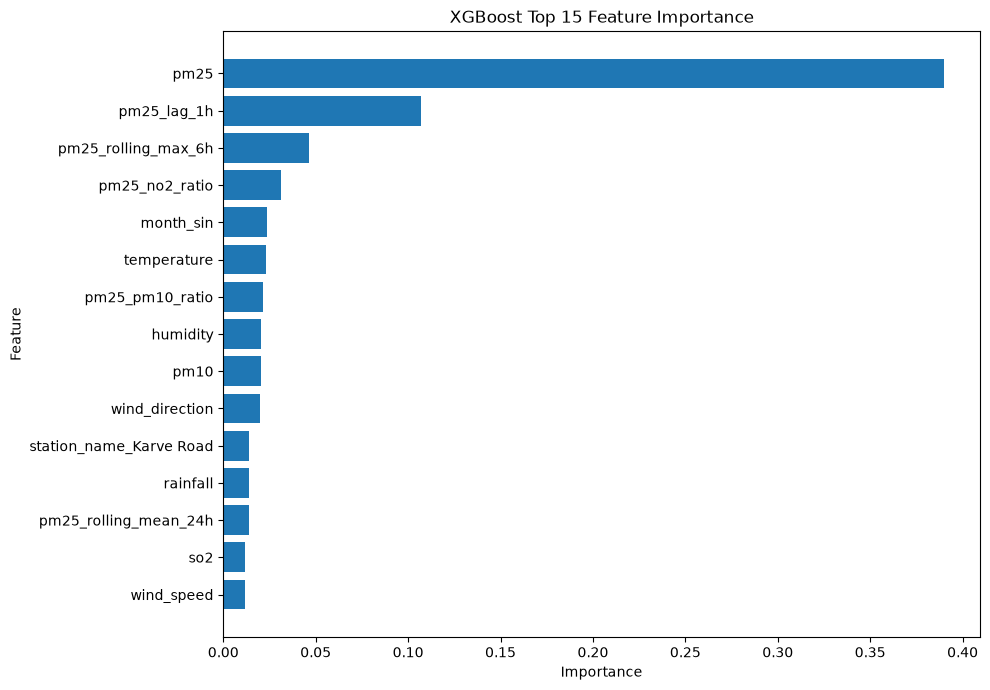

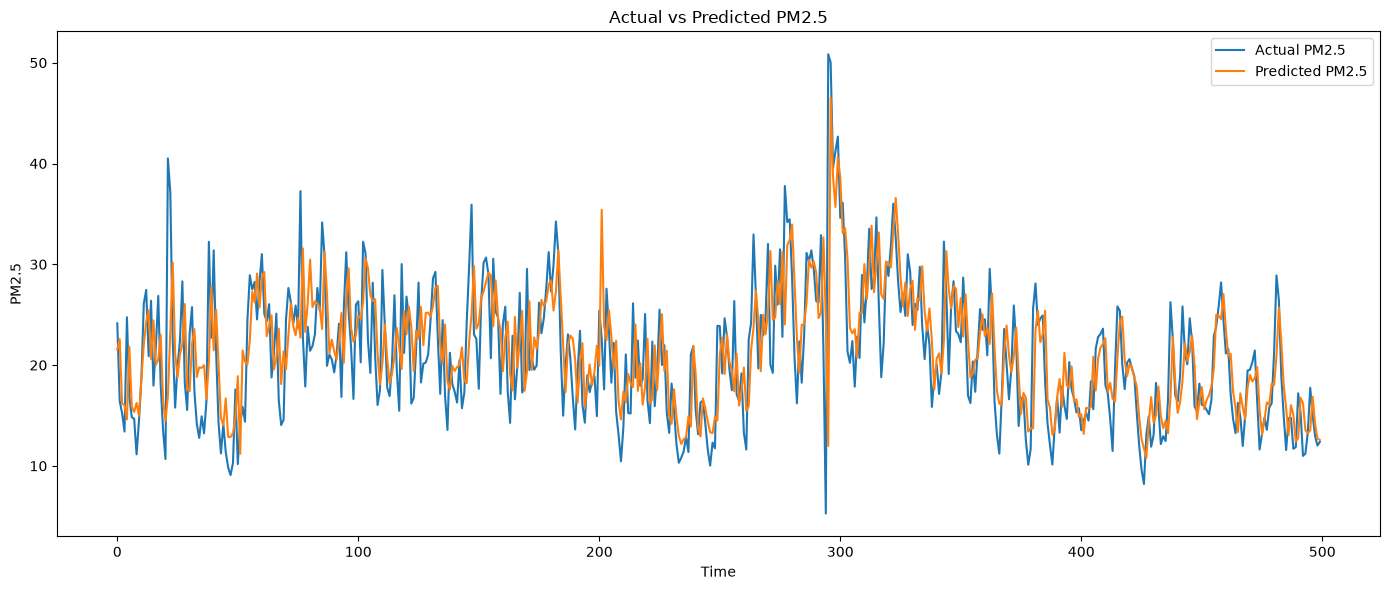


Model saved to: ../models/forecasting/xgboost_pm25_forecasting.pkl
Feature names saved to: ../models/forecasting/feature_names.pkl

FORECASTING PIPELINE COMPLETED


In [ ]:
# ============================================================
# XGBOOST PM2.5 NEXT-HOUR FORECASTING
# Pune CPCB Multi-Station Dataset
# ============================================================

import os
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "../data/processed/pune_cpcb_features.csv"

if not os.path.exists(file_path):
    file_path = "data/processed/pune_cpcb_features.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 2. CONVERT TIMESTAMP
# ============================================================

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df = df.dropna(
    subset=["timestamp"]
)

df = df.sort_values(
    ["station_name", "timestamp"]
).reset_index(
    drop=True
)


# ============================================================
# 3. CREATE NEXT-HOUR TARGET
# ============================================================

# ============================================================
# REMOVE UNWANTED WIND-DIRECTION FEATURES
# ============================================================

remove_features = [
    "wind_direction",
    "wind_direction_sin",
    "wind_direction_cos"
]

df_model = df.drop(
    columns=remove_features,
    errors="ignore"
)


# ============================================================
# ONE-HOT ENCODE STATIONS
# ============================================================

df_model = pd.get_dummies(
    df_model,
    columns=["station_name"],
    dtype=int
)


# ============================================================
# CREATE X AND y
# ============================================================

X = df_model.drop(
    columns=["target_pm25_next_1h"],
    errors="ignore"
)

y = df["target_pm25_next_1h"].copy()


# ============================================================
# REMOVE TIMESTAMP
# ============================================================

if "timestamp" in X.columns:
    X = X.drop(
        columns=["timestamp"]
    )


# ============================================================
# VERIFY
# ============================================================

print("\nWind-direction features remaining:")

print([
    x for x in X.columns
    if x in [
        "wind_direction",
        "wind_direction_sin",
        "wind_direction_cos"
    ]
])


# ============================================================
# 4. REMOVE ROWS WITHOUT TARGET
# ============================================================

df = df.dropna(
    subset=["target_pm25_next_1h"]
).copy()


# ============================================================
# 5. REMOVE NON-FEATURE / UNWANTED COLUMNS
# ============================================================

drop_columns = [

    # Timestamp should not be directly given
    # to XGBoost
    "timestamp",

    # Target must not be part of X
    "target_pm25_next_1h",

    # ========================================================
    # REMOVED FROM MODEL
    # ========================================================

    "wind_direction",
    "wind_direction_sin",
    "wind_direction_cos"
]


print(
    "\nRemoving unwanted columns:"
)

print(
    [
        column
        for column in drop_columns
        if column in df.columns
    ]
)


# Keep station name separately
station_names = df[
    "station_name"
].copy()


# ============================================================
# 6. DROP UNWANTED COLUMNS
# ============================================================

df_model = df.drop(
    columns=drop_columns,
    errors="ignore"
)


# ============================================================
# 7. ONE-HOT ENCODE STATIONS
# ============================================================

df_model = pd.get_dummies(
    df_model,
    columns=["station_name"],
    dtype=int
)


# ============================================================
# 8. CREATE X AND y
# ============================================================

X = df_model.copy()

y = df[
    "target_pm25_next_1h"
].copy()


# ============================================================
# 9. REMOVE TIMESTAMP IF STILL PRESENT
# ============================================================

if "timestamp" in X.columns:

    X = X.drop(
        columns=["timestamp"]
    )


# ============================================================
# 10. CONVERT EVERYTHING TO NUMERIC
# ============================================================

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

y = pd.to_numeric(
    y,
    errors="coerce"
)


# ============================================================
# 11. HANDLE INFINITE VALUES
# ============================================================

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================================
# 12. REMOVE COMPLETELY EMPTY COLUMNS
# ============================================================

empty_columns = X.columns[
    X.isna().all()
].tolist()

if empty_columns:

    print(
        "\nRemoving empty columns:"
    )

    print(
        empty_columns
    )

    X = X.drop(
        columns=empty_columns
    )


# ============================================================
# 13. CHECK FINAL FEATURES
# ============================================================

print(
    "\n================================"
)

print(
    "FINAL MODEL FEATURES"
)

print(
    "================================"
)

print(
    "Total features:",
    len(X.columns)
)

print(
    "\nWind-direction features remaining:"
)

wind_features = [
    column
    for column in X.columns
    if column in [
        "wind_direction",
        "wind_direction_sin",
        "wind_direction_cos"
    ]
]

print(
    wind_features
)


# ============================================================
# 14. TIME-BASED TRAIN TEST SPLIT
# ============================================================

# IMPORTANT:
# Never use random train_test_split for time-series forecasting.

split_time = df[
    "timestamp"
].quantile(
    0.80
)

train_mask = (
    df["timestamp"] <= split_time
)

test_mask = (
    df["timestamp"] > split_time
)

X_train = X.loc[
    train_mask
]

X_test = X.loc[
    test_mask
]

y_train = y.loc[
    train_mask
]

y_test = y.loc[
    test_mask
]


print(
    "\n================================"
)

print(
    "TRAIN / TEST SPLIT"
)

print(
    "================================"
)

print(
    "Split time:",
    split_time
)

print(
    "Training rows:",
    len(X_train)
)

print(
    "Testing rows :",
    len(X_test)
)

print(
    "Train period:",
    df.loc[
        train_mask,
        "timestamp"
    ].min(),
    "to",
    df.loc[
        train_mask,
        "timestamp"
    ].max()
)

print(
    "Test period:",
    df.loc[
        test_mask,
        "timestamp"
    ].min(),
    "to",
    df.loc[
        test_mask,
        "timestamp"
    ].max()
)


# ============================================================
# 15. TRAIN XGBOOST
# ============================================================

model = XGBRegressor(

    n_estimators=1000,

    learning_rate=0.03,

    max_depth=8,

    min_child_weight=5,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="reg:squarederror",

    eval_metric="rmse",

    random_state=42,

    n_jobs=-1,

    tree_method="hist"
)


print(
    "\n================================"
)

print(
    "TRAINING XGBOOST"
)

print(
    "================================"
)

model.fit(
    X_train,
    y_train,

    eval_set=[
        (
            X_train,
            y_train
        ),
        (
            X_test,
            y_test
        )
    ],

    verbose=False
)

print(
    "Training completed!"
)


# ============================================================
# 16. PREDICTION
# ============================================================

y_pred = model.predict(
    X_test
)


# ============================================================
# 17. EVALUATION
# ============================================================

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)


print(
    "\n================================"
)

print(
    "MODEL PERFORMANCE"
)

print(
    "================================"
)

print(
    f"MAE  : {mae:.4f}"
)

print(
    f"RMSE : {rmse:.4f}"
)

print(
    f"R²   : {r2:.4f}"
)

print(
    f"\nR² Percentage: {r2 * 100:.2f}%"
)


# ============================================================
# 18. CREATE PREDICTION DATAFRAME
# ============================================================

predictions = df.loc[
    test_mask,
    [
        "timestamp",
        "station_name",
        "pm25"
    ]
].copy()

predictions[
    "actual_pm25_next_1h"
] = y_test.values

predictions[
    "predicted_pm25_next_1h"
] = y_pred

predictions[
    "error"
] = (
    predictions[
        "actual_pm25_next_1h"
    ]
    -
    predictions[
        "predicted_pm25_next_1h"
    ]
)


# ============================================================
# 19. DISPLAY RESULTS
# ============================================================

print(
    "\nSample predictions:"
)

print(
    predictions.head(20).to_string(
        index=False
    )
)


# ============================================================
# 20. SAVE PREDICTIONS
# ============================================================

prediction_directory = os.path.join(
    PROJECT_ROOT if "PROJECT_ROOT" in globals()
    else ".",
    "data",
    "processed"
)

# Use the project-relative path safely
os.makedirs(
    "data/processed",
    exist_ok=True
)

prediction_path = (
    "data/processed/"
    "xgboost_predictions.csv"
)

predictions.to_csv(
    prediction_path,
    index=False
)

print(
    "\nPredictions saved to:",
    prediction_path
)


# ============================================================
# 21. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({

    "feature": X.columns,

    "importance": (
        model.feature_importances_
    )
})

importance = importance.sort_values(
    "importance",
    ascending=False
)


print(
    "\n================================"
)

print(
    "TOP 20 IMPORTANT FEATURES"
)

print(
    "================================"
)

print(
    importance.head(20).to_string(
        index=False
    )
)


# ============================================================
# 22. FEATURE IMPORTANCE PLOT
# ============================================================

top_features = importance.head(
    15
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features[
        "feature"
    ][::-1],

    top_features[
        "importance"
    ][::-1]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "XGBoost Top 15 Feature Importance"
)

plt.tight_layout()

plt.show()


# ============================================================
# 23. ACTUAL VS PREDICTED
# ============================================================

sample = predictions.head(
    500
)

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    sample[
        "actual_pm25_next_1h"
    ].values,

    label="Actual PM2.5"
)

plt.plot(
    sample[
        "predicted_pm25_next_1h"
    ].values,

    label="Predicted PM2.5"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "PM2.5"
)

plt.title(
    "Actual vs Predicted PM2.5"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 24. SAVE MODEL
# ============================================================

os.makedirs(
    "models/forecasting",
    exist_ok=True
)

model_path = (
    "models/forecasting/"
    "xgboost_pm25_forecasting.pkl"
)

joblib.dump(
    model,
    model_path
)

print(
    "\nModel saved to:",
    model_path
)


# ============================================================
# 25. SAVE FEATURE NAMES
# ============================================================

feature_path = (
    "models/forecasting/"
    "feature_names.pkl"
)

final_feature_names = (
    X.columns.tolist()
)

joblib.dump(
    final_feature_names,
    feature_path
)

print(
    "Feature names saved to:",
    feature_path
)

print(
    "\n================================"
)

print(
    "FINAL FEATURE COUNT:",
    len(final_feature_names)
)

print(
    "================================"
)

print(
    "\nWind-direction features in saved model:"
)

print(
    [
        feature
        for feature in final_feature_names
        if feature in [
            "wind_direction",
            "wind_direction_sin",
            "wind_direction_cos"
        ]
    ]
)


# ============================================================
# 26. COMPLETED
# ============================================================

print(
    "\n================================"
)

print(
    "FORECASTING PIPELINE COMPLETED"
)

print(
    "================================"
)